In [ ]:
!pip install pandas dask[complete] psutil matplotlib pyarrow

In [ ]:
import os
from getpass import getpass

os.environ["KAGGLE_API_TOKEN"] = getpass("Paste your Kaggle API token: ")

Paste your Kaggle API token: ··········


In [ ]:
%pip install -U kagglehub

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.competition_download('new-york-city-taxi-fare-prediction')

print("Path to competition files:", path)

Path to competition files: /root/.cache/kagglehub/competitions/new-york-city-taxi-fare-prediction


In [ ]:
import os
import shutil
import psutil

# 1. عرض الملفات الموجودة في مجلد المسابقة
data_path = "/root/.cache/kagglehub/competitions/new-york-city-taxi-fare-prediction"

for filename in os.listdir(data_path):
    filepath = os.path.join(data_path, filename)

    if os.path.isfile(filepath):
        size_gb = os.path.getsize(filepath) / (1024 ** 3)
        print(f"{filename}: {size_gb:.2f} GB")

# 2. مساحة التخزين المتاحة
disk = shutil.disk_usage("/content")
print(f"\nFree disk space: {disk.free / (1024**3):.2f} GB")

# 3. الذاكرة العشوائية المتاحة
memory = psutil.virtual_memory()
print(f"Total RAM: {memory.total / (1024**3):.2f} GB")
print(f"Available RAM: {memory.available / (1024**3):.2f} GB")

test.csv: 0.00 GB
train.csv: 5.31 GB
sample_submission.csv: 0.00 GB
GCP-Coupons-Instructions.rtf: 0.00 GB

Free disk space: 81.89 GB
Total RAM: 12.67 GB
Available RAM: 11.64 GB


# **Task 1 — Traditional Pandas.**

In [ ]:

import os

file_path = "/root/.cache/kagglehub/competitions/new-york-city-taxi-fare-prediction/train.csv"
print("File exists:", os.path.exists(file_path))


File exists: True


In [ ]:

import pandas as pd
import psutil
import os
import time
import threading
import matplotlib.pyplot as plt
import csv

log_file = "/content/ram_log.csv"
process = psutil.Process(os.getpid())
stop_event = threading.Event()
start = time.perf_counter()

# حفظ القياسات تدريجيا في ملف
def monitor():
    with open(log_file, "w", newline="") as f:
        writer = csv.writer(f)
        writer.writerow([
            "time_sec", "available_ram_gb",
            "python_ram_gb", "system_ram_percent"
        ])
        f.flush()

        while not stop_event.is_set():
            elapsed = time.perf_counter() - start
            available = psutil.virtual_memory().available / 1024**3
            python_ram = process.memory_info().rss / 1024**3
            percent = psutil.virtual_memory().percent

            writer.writerow([
                elapsed, available, python_ram, percent
            ])
            f.flush()  # حفظ القياس فورا
            time.sleep(0.2)

thread = threading.Thread(target=monitor, daemon=True)
thread.start()

try:
    t0 = time.perf_counter()
    df = pd.read_csv(file_path)
    print("Execution time:", round(time.perf_counter() - t0, 2), "seconds")
    print("Dataset shape:", df.shape)
except Exception as e:
    print("Reading stopped:", type(e).__name__, str(e))
finally:
    stop_event.set()
    thread.join(timeout=2)

print("Measurements saved to:", log_file)


Last recorded time: 107.78 seconds
Minimum available RAM: 0.48 GB
Maximum Python RAM: 11.32 GB
Maximum system RAM usage: 96.2 %


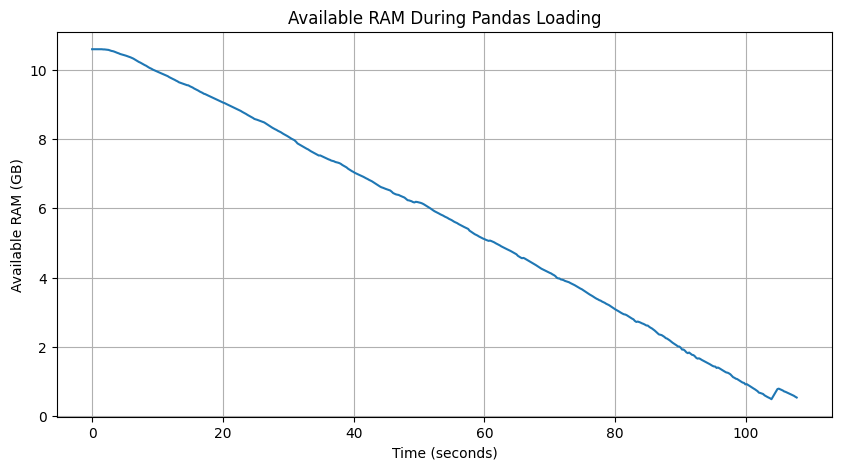

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
import os

log_file = "/content/ram_log.csv"

if os.path.exists(log_file):
    data = pd.read_csv(log_file).dropna()

    if not data.empty:
        print("Last recorded time:", round(data["time_sec"].iloc[-1], 2), "seconds")
        print("Minimum available RAM:", round(data["available_ram_gb"].min(), 2), "GB")
        print("Maximum Python RAM:", round(data["python_ram_gb"].max(), 2), "GB")
        print("Maximum system RAM usage:", round(data["system_ram_percent"].max(), 2), "%")

        plt.figure(figsize=(10, 5))
        plt.plot(data["time_sec"], data["available_ram_gb"])
        plt.xlabel("Time (seconds)")
        plt.ylabel("Available RAM (GB)")
        plt.title("Available RAM During Pandas Loading")
        plt.grid(True)
        plt.show()
    else:
        print("No measurements were recorded.")
else:
    print("Measurement file not found.")


In [ ]:

print(data.tail(5).to_string(index=False))

print("\nMinimum available RAM:",
      round(data["available_ram_gb"].min(), 2), "GB")

print("Maximum Python RAM:",
      round(data["python_ram_gb"].max(), 2), "GB")

print("Maximum system RAM usage:",
      round(data["system_ram_percent"].max(), 2), "%")


  time_sec  available_ram_gb  python_ram_gb  system_ram_percent
106.909801          0.621510      11.226994                95.1
107.145827          0.599110      11.247532                95.3
107.347080          0.581318      11.265121                95.4
107.547622          0.555935      11.290524                95.6
107.778934          0.530590      11.315903                95.8

Minimum available RAM: 0.48 GB
Maximum Python RAM: 11.32 GB
Maximum system RAM usage: 96.2 %


# **Task 2 — Pandas Chunking.**

Mean fare: 11.345045601662948
Execution time: 105.48 seconds
Maximum System RAM Usage: 16.2 %


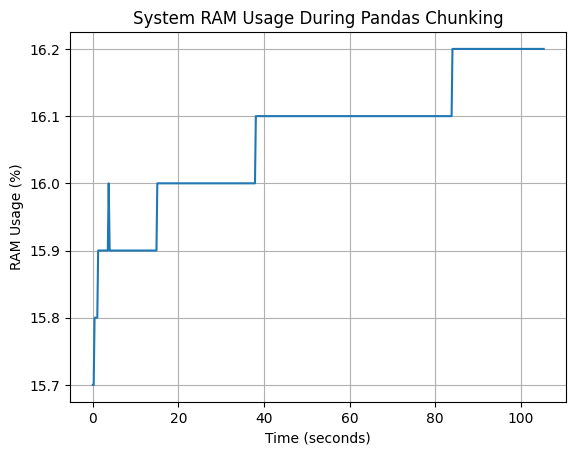

In [ ]:

import pandas as pd
import psutil
import time
import threading
import matplotlib.pyplot as plt

file_path = "/root/.cache/kagglehub/competitions/new-york-city-taxi-fare-prediction/train.csv"

times = []
ram = []
stop = False

def monitor():
    while not stop:
        times.append(time.time() - start)
        ram.append(psutil.virtual_memory().percent)
        time.sleep(0.2)

start = time.time()
thread = threading.Thread(target=monitor)
thread.start()

total = 0
count = 0

try:
    t0 = time.time()

    for chunk in pd.read_csv(file_path, chunksize=100_000):
        total += chunk["fare_amount"].sum()
        count += chunk["fare_amount"].count()

    execution_time = time.time() - t0
    print("Mean fare:", total / count)
    print("Execution time:", round(execution_time, 2), "seconds")

finally:
    stop = True
    thread.join()

max_ram = max(ram)
print("Maximum System RAM Usage:", round(max_ram, 2), "%")

plt.plot(times, ram)
plt.xlabel("Time (seconds)")
plt.ylabel("RAM Usage (%)")
plt.title("System RAM Usage During Pandas Chunking")
plt.grid()
plt.show()


# **Task 3 — Dask DataFrame.**

Mean fare: 11.345045601662935
Execution time: 93.95 seconds
Maximum System RAM Usage: 16.7 %


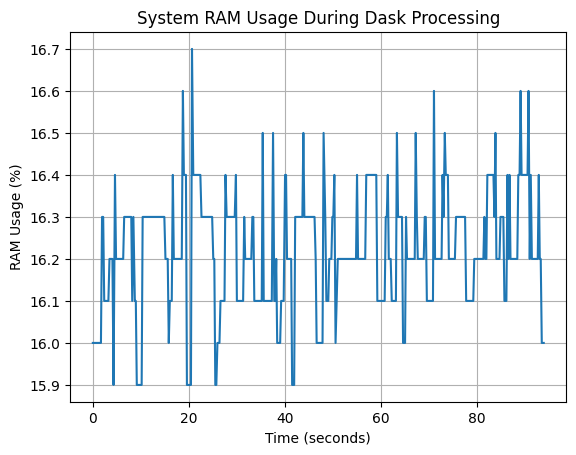

In [ ]:

import dask.dataframe as dd
import psutil
import time
import threading
import matplotlib.pyplot as plt

times = []
ram = []
stop = False

def monitor():
    while not stop:
        times.append(time.time() - start)
        ram.append(psutil.virtual_memory().percent)
        time.sleep(0.2)

start = time.time()
thread = threading.Thread(target=monitor)
thread.start()

try:
    t0 = time.time()

    df = dd.read_csv(file_path)
    mean_fare = df["fare_amount"].mean().compute()

    execution_time = time.time() - t0
    print("Mean fare:", mean_fare)
    print("Execution time:", round(execution_time, 2), "seconds")

finally:
    stop = True
    thread.join()

max_ram = max(ram)
print("Maximum System RAM Usage:", round(max_ram, 2), "%")

plt.plot(times, ram)
plt.xlabel("Time (seconds)")
plt.ylabel("RAM Usage (%)")
plt.title("System RAM Usage During Dask Processing")
plt.grid()
plt.show()


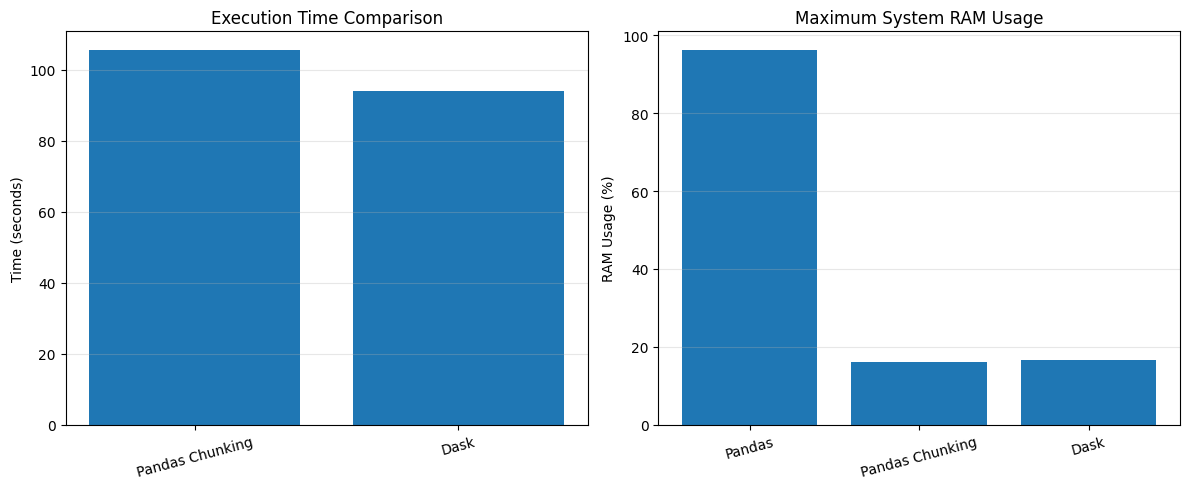

In [ ]:

import matplotlib.pyplot as plt
import numpy as np

tasks = ["Pandas", "Pandas Chunking", "Dask"]

execution_time = [np.nan, 105.48, 93.95]
ram_usage = [96.2, 16.2, 16.7]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# مقارنة وقت التنفيذ
axes[0].bar(tasks, execution_time)
axes[0].set_title("Execution Time Comparison")
axes[0].set_ylabel("Time (seconds)")
axes[0].tick_params(axis="x", rotation=15)

# مقارنة أقصى استهلاك لذاكرة النظام
axes[1].bar(tasks, ram_usage)
axes[1].set_title("Maximum System RAM Usage")
axes[1].set_ylabel("RAM Usage (%)")
axes[1].tick_params(axis="x", rotation=15)

for ax in axes:
    ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()
